# 六種 CNN 架構比較：遷移學習 vs. 從零訓練（貓狗分類）

深度學習課程實作，2025/11/04。

- 資料：貓狗照片，訓練 60 張、驗證 61 張，另有 2 張測試照片
- LeNet 從零開始訓練（15 epochs）
- VGG16、ResNet50、InceptionV3、MobileNetV1、EfficientNetB0：載入 ImageNet 預訓練權重並凍結，只訓練新加的分類層（10 epochs）

> 需在 Google Colab 執行，並自行準備 `data/train`、`data/validation`、`data/test` 資料夾（`cats/`、`dogs/` 兩類）。

In [ ]:
from google.colab import drive

drive.mount('/content/drive')
%cd /content/drive/MyDrive/[0]2025深度學習/1104/data

In [ ]:
%ls

test/  train/  validation/


## 1. LeNet（從零訓練）

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
import os
import numpy as np

# --- 0. 設定路徑和參數 ---

# ！！請先修改這個基礎路徑
BASE_DATA_DIR = '/content/drive/MyDrive/[0]2025深度學習/1104/data/' # 請改成自己的資料路徑

train_dir = os.path.join(BASE_DATA_DIR, 'train')
validation_dir = os.path.join(BASE_DATA_DIR, 'validation')
test_dir = os.path.join(BASE_DATA_DIR, 'test') # 預測時會用到

IMG_SIZE = 128
BATCH_SIZE = 64

# --- 1. 準備資料 (Tain 和 Validation) ---

print("正在從資料夾載入訓練資料...")
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    label_mode='binary',
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE
)

print("正在從資料夾載入驗證資料...")
val_ds = tf.keras.utils.image_dataset_from_directory(
    validation_dir,
    label_mode='binary',
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE
)

# 獲取類別名稱 (例如 ['cats', 'dogs'])
class_names = train_ds.class_names
print(f"✅ 資料準備完成。類別: {class_names}")

# 優化效能
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)


# --- 2. 建立【LeNet】模型 ---

def build_lenet(input_shape):
    model = models.Sequential(name="LeNet_for_CatsDogs")

    # Rescaling layer (applies 1/255 scaling)
    model.add(layers.Rescaling(1./255, input_shape=input_shape))

    # C1: Convolutional layer with 6 filters, 5x5 kernel, Tanh activation
    model.add(layers.Conv2D(6, (5, 5), activation='tanh'))
    # S2: Average pooling layer with 2x2 pool size
    model.add(layers.AveragePooling2D((2, 2)))

    # C3: Convolutional layer with 16 filters, 5x5 kernel, Tanh activation
    model.add(layers.Conv2D(16, (5, 5), activation='tanh'))
    # S4: Average pooling layer with 2x2 pool size
    model.add(layers.AveragePooling2D((2, 2)))

    # Flatten the feature maps for the fully connected layers
    model.add(layers.Flatten())

    # F5: Fully connected layer with 120 units, Tanh activation
    model.add(layers.Dense(120, activation='tanh'))

    # F6: Fully connected layer with 84 units, Tanh activation
    model.add(layers.Dense(84, activation='tanh'))

    # Output layer: 1 unit for binary classification with Sigmoid activation
    model.add(layers.Dense(1, activation='sigmoid'))

    return model

model = build_lenet((IMG_SIZE, IMG_SIZE, 3))
model.summary()


# --- 3. 編譯與訓練模型 ---

model.compile(
    optimizer='adam', # Adam 通常是最好的起始點
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("🚀 開始訓練【LeNet】模型...")
history = model.fit(
    train_ds,
    epochs=15, # 我們可以多訓練幾個 epoch，因為模型更強
    validation_data=val_ds
)

print("✅ 訓練完成")

# --- 4. 在 Test 圖片上進行預測 ---
print("🧪 開始在 test 資料夾的圖片上進行預測...")

image_paths = []
allowed_extensions = ('.jpg', '.png', '.jpeg') # 定義允許的圖片副檔名

if os.path.exists(test_dir):
    for filename in os.listdir(test_dir):
        if filename.lower().endswith(allowed_extensions):
            image_paths.append(os.path.join(test_dir, filename))
else:
    print(f"錯誤：測試資料夾 '{test_dir}' 不存在。")

print(f"找到了 {len(image_paths)} 張測試圖片: {image_paths}")

for img_path in image_paths:
    img = tf.keras.utils.load_img(
        img_path, target_size=(IMG_SIZE, IMG_SIZE)
    )
    img_array = tf.keras.utils.img_to_array(img)
    img_batch = tf.expand_dims(img_array, 0)

    prediction = model.predict(img_batch)

    score = prediction[0][0]

    print(f"\n--- 檔案: {os.path.basename(img_path)} ---")
    print(f"原始分數: {score:.4f}")

    if score > 0.5:
        print(f"預測結果: {class_names[1]} ({score*100:.2f}%)")
    else:
        print(f"預測結果: {class_names[0]} ({(1-score)*100:.2f}%)")

# --- 5. 繪製訓練歷史 ---

def plot_history(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']

    epochs = range(1, len(acc) + 1)

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(epochs, acc, 'bo-', label='Training Acc')
    plt.plot(epochs, val_acc, 'ro-', label='Validation Acc')
    plt.title('Training and Validation Accuracy')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs, loss, 'bo-', label='Training Loss')
    plt.plot(epochs, val_loss, 'ro-', label='Validation Loss')
    plt.title('Training and Validation Loss')
    plt.legend()

    plt.show()

正在從資料夾載入訓練資料...
Found 60 files belonging to 2 classes.
正在從資料夾載入驗證資料...
Found 61 files belonging to 2 classes.
✅ 資料準備完成。類別: ['cat', 'dog']


/usr/local/lib/python3.12/dist-packages/keras/src/layers/preprocessing/tf_data_layer.py:19: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "LeNet_for_CatsDogs"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_4 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 124, 124, 6)    │           456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 62, 62, 6)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 58, 58, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 29, 29, 16)     │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 13456)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 120)            │     1,614,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 1)              │            85 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,627,961 (6.21 MB)

 Trainable params: 1,627,961 (6.21 MB)

 Non-trainable params: 0 (0.00 B)

🚀 開始訓練【LeNet】模型...
Epoch 1/15
1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step - accuracy: 0.5000 - loss: 0.7862 - val_accuracy: 0.5082 - val_loss: 3.3964
Epoch 2/15
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.5000 - loss: 3.4337 - val_accuracy: 0.5082 - val_loss: 3.0083
Epoch 3/15
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - accuracy: 0.5000 - loss: 3.0260 - val_accuracy: 0.5082 - val_loss: 2.0230
Epoch 4/15
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.5000 - loss: 2.0067 - val_accuracy: 0.4098 - val_loss: 0.7715
Epoch 5/15
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.6167 - loss: 0.6699 - val_accuracy: 0.4918 - val_loss: 2.3844
Epoch 6/15
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.5000 - loss: 2.2713 - val_accuracy: 0.4918 - val_loss: 1.4406
Epoch 7/15
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - accuracy: 0.5000 - loss: 1.3711 - val_accuracy: 0.4918 - val_loss: 0.8567
Epoch 8/15
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.5000 - loss: 0.8021 - val_accuracy: 0.5082 - 

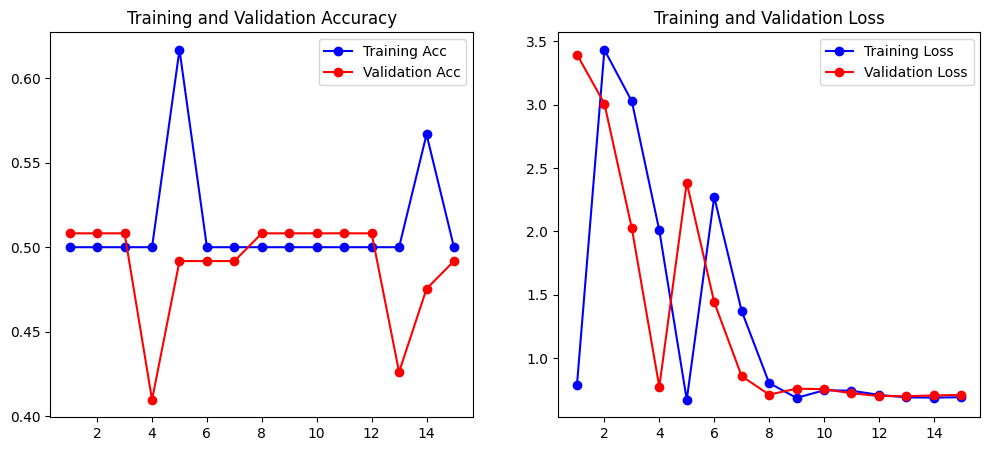

In [ ]:
plot_history(history)

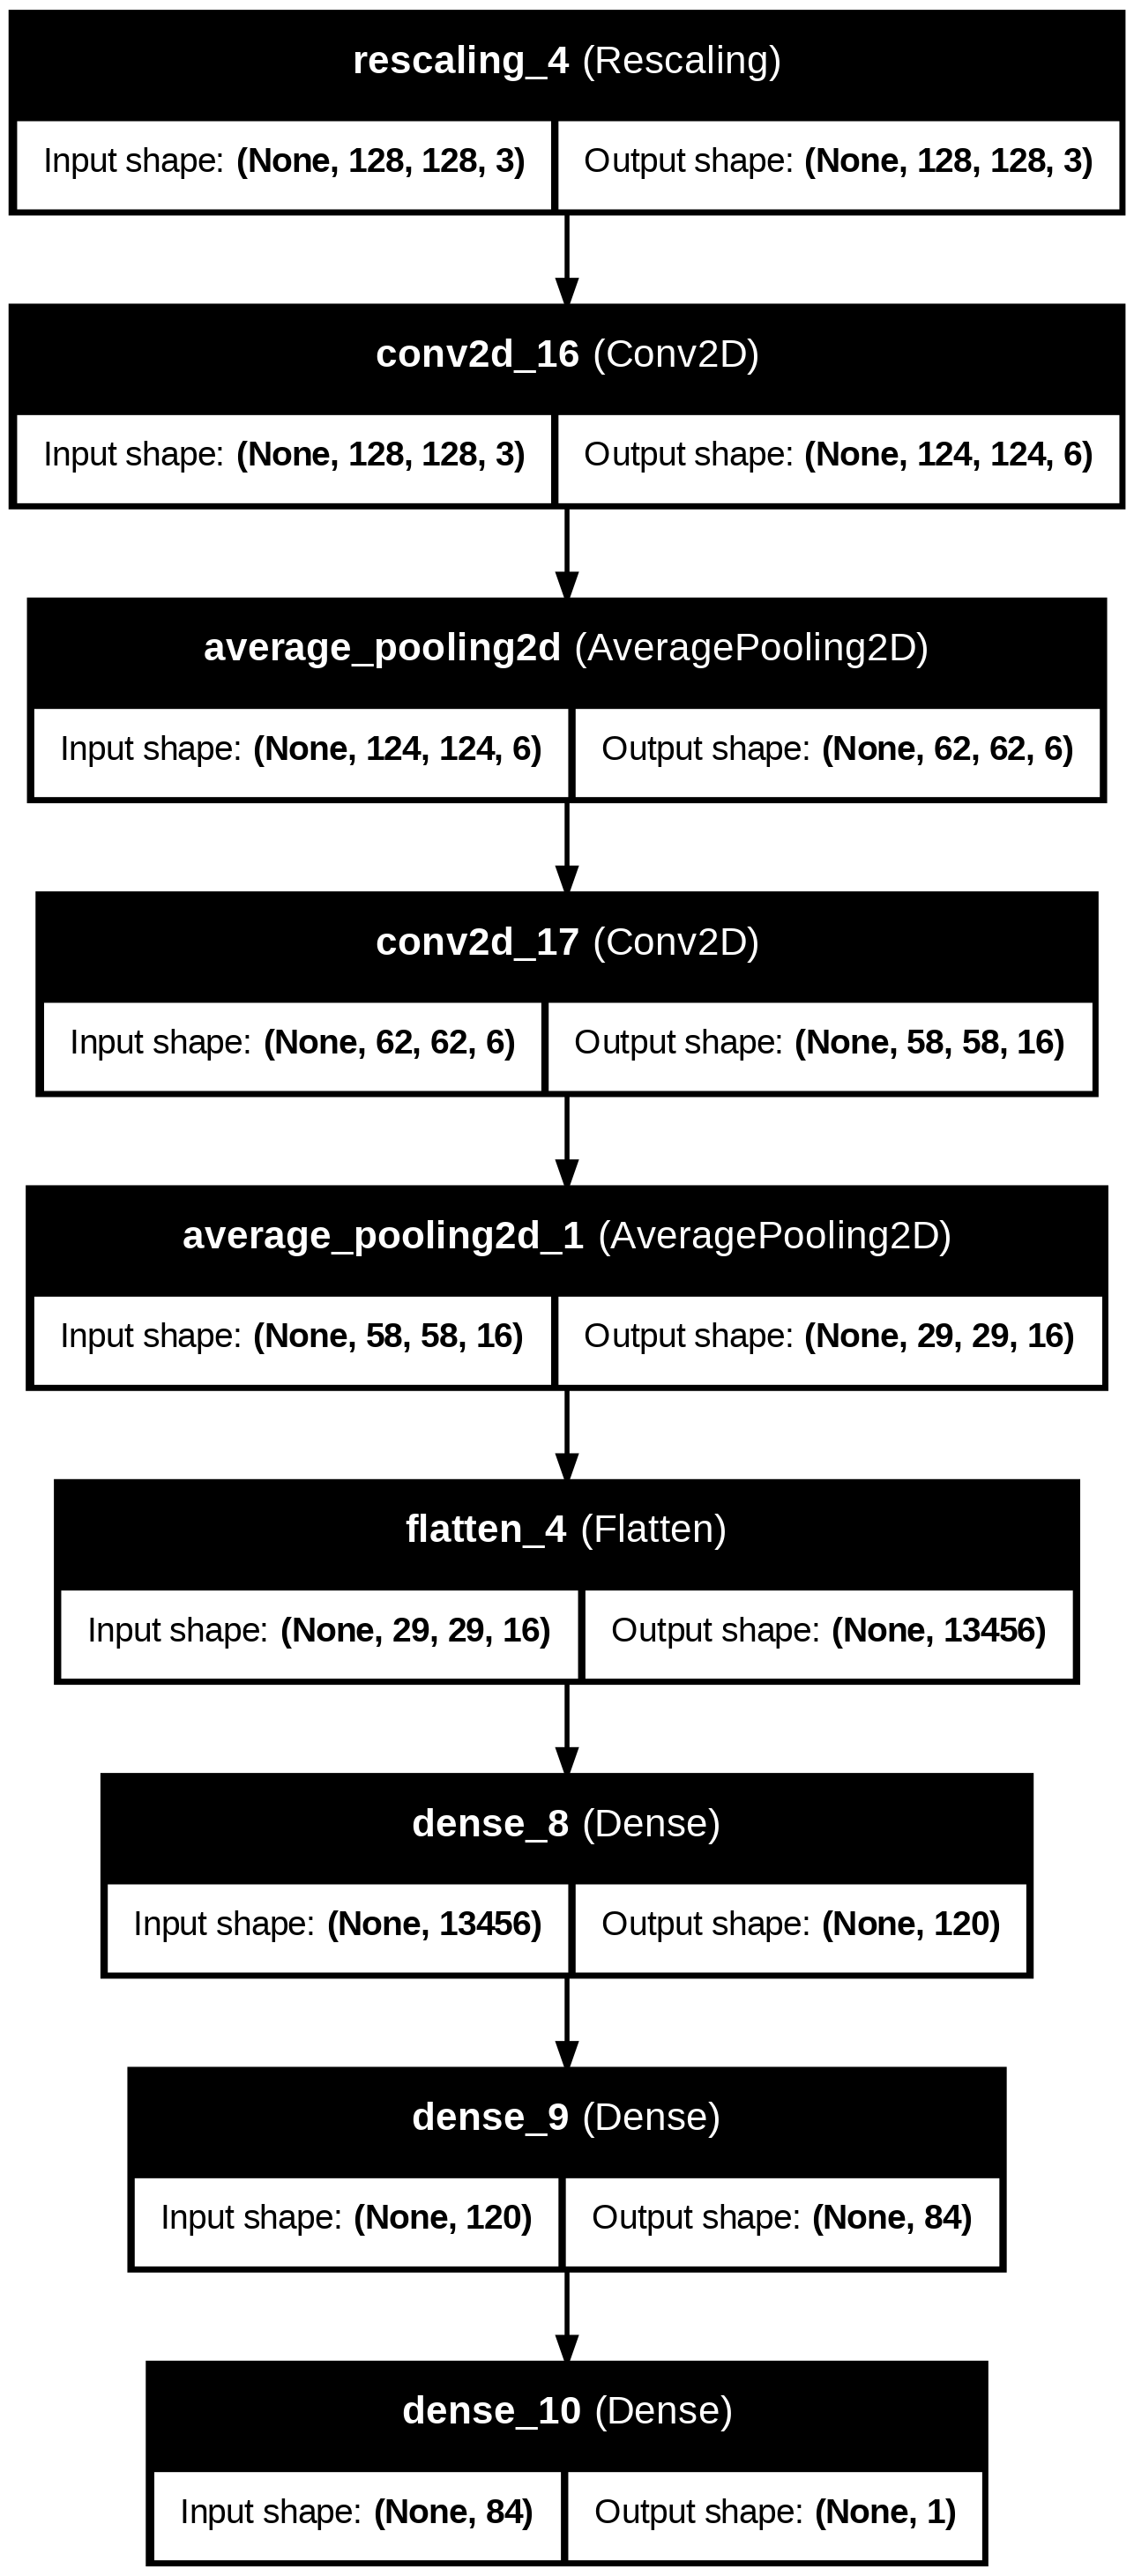

In [ ]:
tf.keras.utils.plot_model(model, show_shapes=True, show_layer_names=True, to_file='lenet_model_structure.png')
from IPython.display import Image
Image(filename='lenet_model_structure.png')

## 2. VGG16（遷移學習）

TensorFlow 版本: 2.19.0
正在從資料夾載入訓練資料...
Found 60 files belonging to 2 classes.
正在從資料夾載入驗證資料...
Found 61 files belonging to 2 classes.
✅ 資料準備完成。類別: ['cat', 'dog']
正在檢查測試資料夾結構以載入測試資料集...
⚠️ 警告：測試資料夾 '/content/drive/MyDrive/[0]2025深度學習/1104/data/test' 未包含預期的類別子資料夾 (例如 'cat/' 和 'dog/')，或資料夾為空。
將跳過測試資料集 (test_ds_raw) 的創建，您可以手動載入圖片進行預測。


Model: "functional_61"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 128, 128, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 128, 128, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 64, 64, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 64, 64, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 32, 32, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 32, 32, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 32, 32, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 16, 16, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 16, 16, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 16, 16, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 8, 8, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 8, 8, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 8, 8, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 8, 8, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 4, 4, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,846,273 (56.63 MB)

 Trainable params: 131,585 (514.00 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

🚀 開始訓練 VGG16 遷移學習模型...
Epoch 1/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 21s 21s/step - accuracy: 0.6167 - loss: 3.2613 - val_accuracy: 0.6230 - val_loss: 2.2582
Epoch 2/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 208ms/step - accuracy: 0.6833 - loss: 3.1397 - val_accuracy: 0.6066 - val_loss: 2.0724
Epoch 3/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 205ms/step - accuracy: 0.5833 - loss: 3.2987 - val_accuracy: 0.6393 - val_loss: 1.9057
Epoch 4/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 206ms/step - accuracy: 0.5833 - loss: 4.4475 - val_accuracy: 0.6721 - val_loss: 1.7537
Epoch 5/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 213ms/step - accuracy: 0.6667 - loss: 3.0316 - val_accuracy: 0.6557 - val_loss: 1.6218
Epoch 6/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 206ms/step - accuracy: 0.5667 - loss: 2.4078 - val_accuracy: 0.6885 - val_loss: 1.5105
Epoch 7/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 205ms/step - accuracy: 0.6833 - loss: 2.7959 - val_accuracy: 0.7377 - val_loss: 1.4211
Epoch 8/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 205ms/step - accuracy: 0.6833 - loss: 2.4201 - val_accura

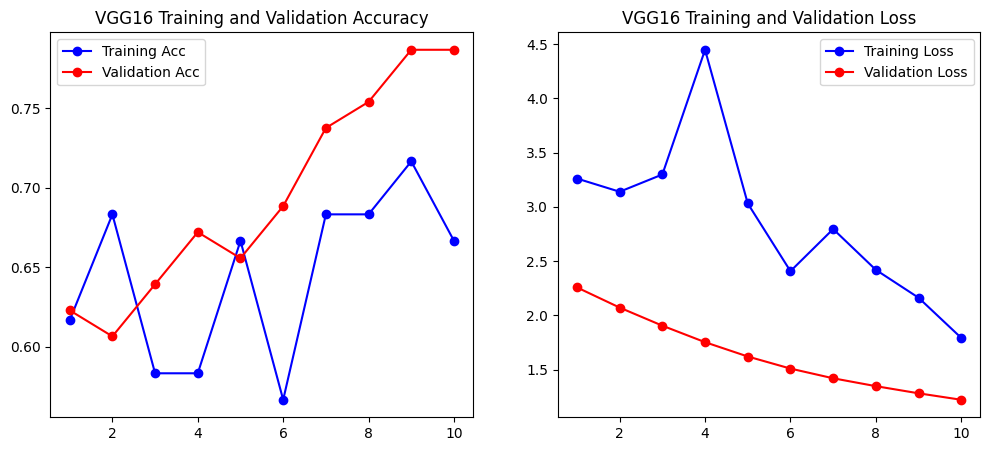

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
import os # Added for path operations
import glob # For listing files in the test directory
import matplotlib.pyplot as plt # For plotting history

print(f"TensorFlow 版本: {tf.__version__}")

# --- 0. 設定路徑和參數 (使用先前定義的基礎路徑) ---

# ！！請改成自己的資料根目錄
BASE_DATA_DIR = '/content/drive/MyDrive/[0]2025深度學習/1104/data/'

train_dir = os.path.join(BASE_DATA_DIR, 'train')
validation_dir = os.path.join(BASE_DATA_DIR, 'validation')
test_dir = os.path.join(BASE_DATA_DIR, 'test') # 將用於測試

# 定義圖片大小和批次大小 (與LeNet模型相同)
IMG_SIZE = 128 # 更改為 128
BATCH_SIZE = 64 # 更改為 64

# --- 1. 載入與準備資料 (從本地資料夾) ---

print("正在從資料夾載入訓練資料...")
train_ds_raw = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    label_mode='binary',
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE
)

print("正在從資料夾載入驗證資料...")
validation_ds_raw = tf.keras.utils.image_dataset_from_directory(
    validation_dir,
    label_mode='binary',
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE
)

# 獲取類別名稱 (例如 ['cat', 'dog'])
class_names = train_ds_raw.class_names
print(f"✅ 資料準備完成。類別: {class_names}")

print("正在檢查測試資料夾結構以載入測試資料集...")

# 檢查 test_dir 是否包含預期的類別子資料夾 (例如 'cat/' 和 'dog/')
# 如果沒有，我們就不使用 image_dataset_from_directory 創建 test_ds_raw

is_flat_test_dir = True
if os.path.exists(test_dir):
    for item in os.listdir(test_dir):
        if os.path.isdir(os.path.join(test_dir, item)):
            is_flat_test_dir = False
            break

if not is_flat_test_dir:
    try:
        test_ds_raw = tf.keras.utils.image_dataset_from_directory(
            test_dir,
            label_mode='binary',
            image_size=(IMG_SIZE, IMG_SIZE),
            batch_size=BATCH_SIZE
        )
        print(f"✅ 測試資料集載入完成。類別: {test_ds_raw.class_names}")
    except ValueError as e:
        print(f"⚠️ 警告：嘗試載入測試資料集時發生錯誤: {e}")
        print("這可能是因為測試資料夾的結構不符合 image_dataset_from_directory 的要求。將跳過測試資料集 (test_ds_raw) 的創建。")
        test_ds_raw = None
else:
    print(f"⚠️ 警告：測試資料夾 '{test_dir}' 未包含預期的類別子資料夾 (例如 'cat/' 和 'dog/')，或資料夾為空。")
    print("將跳過測試資料集 (test_ds_raw) 的創建，您可以手動載入圖片進行預測。")
    test_ds_raw = None


# 建立前處理函式
# 注意：tf.image.resize 預設會將圖像像素轉換為 float32，
# preprocess_input 也會處理這一點，並對 VGG16 進行特定的標準化。
def format_image(image, label):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = preprocess_input(image) # 使用 VGG16 專用的預處理
    return image, label

# 優化效能
AUTOTUNE = tf.data.AUTOTUNE

# 應用前處理並批次化資料 (使用 raw datasets)
train_dataset = train_ds_raw.map(format_image).cache().prefetch(buffer_size=AUTOTUNE)
validation_dataset = validation_ds_raw.map(format_image).cache().prefetch(buffer_size=AUTOTUNE)

if test_ds_raw is not None:
    test_dataset = test_ds_raw.map(format_image).cache().prefetch(buffer_size=AUTOTUNE)
else:
    test_dataset = None # 如果 test_ds_raw 未創建，則 test_dataset 也為 None


# --- 2. 建立遷移學習模型 ---

# (1) 載入 VGG16 基礎模型 (不含頂層分類器)
base_model = VGG16(
    input_shape=(IMG_SIZE, IMG_SIZE, 3), # (128, 128, 3)
    include_top=False,          # 關鍵：不載入最後的全連接層
    weights='imagenet'          # 使用 ImageNet 預訓練權重
)

# (2) 凍結 VGG16 的捲積基底，使其權重在訓練期間不被更新
base_model.trainable = False

# 創建新的模型，在 VGG16 基礎上添加自定義分類層
x = base_model.output
x = GlobalAveragePooling2D()(x) # 全局平均池化，將特徵圖展平
x = Dense(256, activation='relu')(x) # 添加一個全連接層
x = Dropout(0.5)(x) # 添加 Dropout 防止過擬合
predictions = Dense(1, activation='sigmoid')(x) # 輸出層，二元分類使用 sigmoid

model_vgg16 = Model(inputs=base_model.input, outputs=predictions)

model_vgg16.summary()

# --- 3. 編譯與訓練模型 ---

model_vgg16.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("🚀 開始訓練 VGG16 遷移學習模型...")
history_vgg16 = model_vgg16.fit(
    train_dataset,
    epochs=10, # 可以調整 epoch 數量
    validation_data=validation_dataset
)

print("✅ 訓練完成")

# --- 4. 評估模型 (如果 test_dataset 存在) ---
if test_dataset is not None:
    print("🧪 開始評估 VGG16 模型在測試資料集上的表現...")
    loss, accuracy = model_vgg16.evaluate(test_dataset)
    print(f"測試集損失: {loss:.4f}")
    print(f"測試集準確度: {accuracy:.4f}")
else:
    print("⚠️ 未創建測試資料集 (test_dataset)，跳過模型評估。")

# --- 5. 在 Test 圖片上進行預測 (手動載入) ---
print("🧪 開始在 test 資料夾的圖片上進行預測 (手動載入圖片)...")

image_paths = []
allowed_extensions = ('.jpg', '.png', '.jpeg') # 定義允許的圖片副檔名

if os.path.exists(test_dir):
    for filename in os.listdir(test_dir):
        if filename.lower().endswith(allowed_extensions):
            image_paths.append(os.path.join(test_dir, filename))
else:
    print(f"錯誤：測試資料夾 '{test_dir}' 不存在。")

print(f"找到了 {len(image_paths)} 張測試圖片: {image_paths}")

for img_path in image_paths:
    img = tf.keras.utils.load_img(
        img_path, target_size=(IMG_SIZE, IMG_SIZE)
    )
    img_array = tf.keras.utils.img_to_array(img)
    # VGG16 專用預處理
    img_array_preprocessed = preprocess_input(img_array)
    img_batch = tf.expand_dims(img_array_preprocessed, 0)

    prediction = model_vgg16.predict(img_batch)

    score = prediction[0][0]

    print(f"\n--- 檔案: {os.path.basename(img_path)} ---")
    print(f"原始分數: {score:.4f}")

    if score > 0.5:
        print(f"預測結果: {class_names[1]} ({score*100:.2f}%)")
    else:
        print(f"預測結果: {class_names[0]} ({(1-score)*100:.2f}%)")

# --- 6. 繪製訓練歷史 (VGG16 模型) ---
def plot_history_vgg16(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']

    epochs = range(1, len(acc) + 1)

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(epochs, acc, 'bo-', label='Training Acc')
    plt.plot(epochs, val_acc, 'ro-', label='Validation Acc')
    plt.title('VGG16 Training and Validation Accuracy')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs, loss, 'bo-', label='Training Loss')
    plt.plot(epochs, val_loss, 'ro-', label='Validation Loss')
    plt.title('VGG16 Training and Validation Loss')
    plt.legend()

    plt.show()

# 呼叫繪圖函式
plot_history_vgg16(history_vgg16)


## 3. ResNet50（遷移學習）

TensorFlow 版本: 2.19.0
正在從資料夾載入訓練資料...
Found 60 files belonging to 2 classes.
正在從資料夾載入驗證資料...
Found 61 files belonging to 2 classes.
✅ 資料準備完成。類別: ['cat', 'dog']
⚠️ 警告：測試資料夾未包含預期的類別子資料夾，將跳過測試資料集 (test_ds_raw) 的創建，您可以手動載入圖片進行預測。
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_62"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_7       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 134, 134,  │          0 │ input_layer_7[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 64, 64,    │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 64, 64,    │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 64, 64,    │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 66, 66,    │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 32, 32,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 32, 32,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 32, 32,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 32, 32,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 32, 32,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 32, 32,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 32, 32,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 32, 32,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 32, 32,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 32, 32,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 32, 32,    │      1,024 │ conv2_block1_3_c

 Total params: 24,112,513 (91.98 MB)

 Trainable params: 524,801 (2.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

🚀 開始訓練 ResNet50 遷移學習模型...
Epoch 1/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 19s 19s/step - accuracy: 0.5833 - loss: 0.9986 - val_accuracy: 0.7377 - val_loss: 0.5732
Epoch 2/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step - accuracy: 0.6000 - loss: 0.9735 - val_accuracy: 0.7705 - val_loss: 0.4905
Epoch 3/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step - accuracy: 0.6667 - loss: 0.6260 - val_accuracy: 0.8197 - val_loss: 0.4193
Epoch 4/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step - accuracy: 0.7833 - loss: 0.4229 - val_accuracy: 0.8197 - val_loss: 0.3661
Epoch 5/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step - accuracy: 0.8333 - loss: 0.3780 - val_accuracy: 0.8197 - val_loss: 0.3299
Epoch 6/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - accuracy: 0.8500 - loss: 0.3067 - val_accuracy: 0.8361 - val_loss: 0.3037
Epoch 7/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step - accuracy: 0.8167 - loss: 0.3365 - val_accuracy: 0.8689 - val_loss: 0.2797
Epoch 8/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step - accuracy: 0.8833 - loss: 0.2733 - val_acc

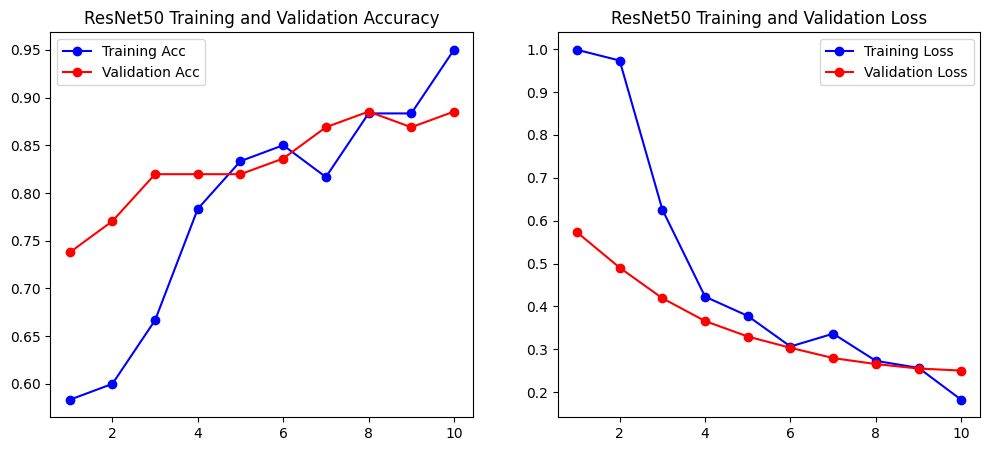

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.applications import ResNet50 # Import ResNet50
from tensorflow.keras.applications.resnet import preprocess_input as resnet_preprocess_input # Import ResNet-specific preprocess
import os
import glob
import matplotlib.pyplot as plt

print(f"TensorFlow 版本: {tf.__version__}")

# --- 0. 設定路徑和參數 (與VGG16和LeNet模型相同) ---
BASE_DATA_DIR = '/content/drive/MyDrive/[0]2025深度學習/1104/data/'
train_dir = os.path.join(BASE_DATA_DIR, 'train')
validation_dir = os.path.join(BASE_DATA_DIR, 'validation')
test_dir = os.path.join(BASE_DATA_DIR, 'test')

IMG_SIZE = 128
BATCH_SIZE = 64

# --- 1. 載入與準備資料 (從本地資料夾，與VGG16模型相同，但使用ResNet預處理) ---

print("正在從資料夾載入訓練資料...")
train_ds_raw = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    label_mode='binary',
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE
)

print("正在從資料夾載入驗證資料...")
validation_ds_raw = tf.keras.utils.image_dataset_from_directory(
    validation_dir,
    label_mode='binary',
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE
)

class_names = train_ds_raw.class_names
print(f"✅ 資料準備完成。類別: {class_names}")

# 由於test資料夾結構不符合image_dataset_from_directory，所以跳過創建test_ds_raw
# 並保持test_dataset為None，手動載入圖片進行預測
test_ds_raw = None # 確保 test_ds_raw 不被意外創建
test_dataset = None
print("⚠️ 警告：測試資料夾未包含預期的類別子資料夾，將跳過測試資料集 (test_ds_raw) 的創建，您可以手動載入圖片進行預測。")

# 建立前處理函式 - 使用 ResNet 專用的預處理
def format_image_resnet(image, label):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = resnet_preprocess_input(image) # 使用 ResNet 專用的預處理
    return image, label

AUTOTUNE = tf.data.AUTOTUNE

train_dataset_resnet = train_ds_raw.map(format_image_resnet).cache().prefetch(buffer_size=AUTOTUNE)
validation_dataset_resnet = validation_ds_raw.map(format_image_resnet).cache().prefetch(buffer_size=AUTOTUNE)

# --- 2. 建立遷移學習模型 (ResNet50) ---

# (1) 載入 ResNet50 基礎模型 (不含頂層分類器)
base_model_resnet = ResNet50(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights='imagenet'
)

# (2) 凍結 ResNet50 的捲積基底
base_model_resnet.trainable = False

# 創建新的模型，在 ResNet50 基礎上添加自定義分類層
x = base_model_resnet.output
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)
predictions = Dense(1, activation='sigmoid')(x)

model_resnet = Model(inputs=base_model_resnet.input, outputs=predictions)

model_resnet.summary()

# --- 3. 編譯與訓練模型 ---

model_resnet.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("🚀 開始訓練 ResNet50 遷移學習模型...")
history_resnet = model_resnet.fit(
    train_dataset_resnet,
    epochs=10, # 可以調整 epoch 數量
    validation_data=validation_dataset_resnet
)

print("✅ 訓練完成")

# --- 4. 評估模型 (如果 test_dataset 存在，但我們跳過了) ---
if test_dataset is not None:
    print("🧪 開始評估 ResNet50 模型在測試資料集上的表現...")
    loss, accuracy = model_resnet.evaluate(test_dataset)
    print(f"測試集損失: {loss:.4f}")
    print(f"測試集準確度: {accuracy:.4f}")
else:
    print("⚠️ 未創建測試資料集 (test_dataset)，跳過模型評估。")

# --- 5. 在 Test 圖片上進行預測 (手動載入) ---
print("🧪 開始在 test 資料夾的圖片上進行預測 (手動載入圖片)...")

image_paths = []
allowed_extensions = ('.jpg', '.png', '.jpeg')

if os.path.exists(test_dir):
    for filename in os.listdir(test_dir):
        if filename.lower().endswith(allowed_extensions):
            image_paths.append(os.path.join(test_dir, filename))
else:
    print(f"錯誤：測試資料夾 '{test_dir}' 不存在。")

print(f"找到了 {len(image_paths)} 張測試圖片: {image_paths}")

for img_path in image_paths:
    img = tf.keras.utils.load_img(
        img_path, target_size=(IMG_SIZE, IMG_SIZE)
    )
    img_array = tf.keras.utils.img_to_array(img)
    # 使用 ResNet 專用預處理
    img_array_preprocessed = resnet_preprocess_input(img_array)
    img_batch = tf.expand_dims(img_array_preprocessed, 0)

    prediction = model_resnet.predict(img_batch)

    score = prediction[0][0]

    print(f"\n--- 檔案: {os.path.basename(img_path)} ---")
    print(f"原始分數: {score:.4f}")

    if score > 0.5:
        print(f"預測結果: {class_names[1]} ({score*100:.2f}%)")
    else:
        print(f"預測結果: {class_names[0]} ({(1-score)*100:.2f}%)")

# --- 6. 繪製訓練歷史 (ResNet 模型) ---
def plot_history_resnet(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']

    epochs = range(1, len(acc) + 1)

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(epochs, acc, 'bo-', label='Training Acc')
    plt.plot(epochs, val_acc, 'ro-', label='Validation Acc')
    plt.title('ResNet50 Training and Validation Accuracy')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs, loss, 'bo-', label='Training Loss')
    plt.plot(epochs, val_loss, 'ro-', label='Validation Loss')
    plt.title('ResNet50 Training and Validation Loss')
    plt.legend()

    plt.show()

# 呼叫繪圖函式
plot_history_resnet(history_resnet)


## 4. InceptionV3（遷移學習）

TensorFlow 版本: 2.19.0
正在從資料夾載入訓練資料...
Found 60 files belonging to 2 classes.
正在從資料夾載入驗證資料...
Found 61 files belonging to 2 classes.
✅ 資料準備完成。類別: ['cat', 'dog']
⚠️ 警告：測試資料夾未包含預期的類別子資料夾，將跳過測試資料集 (test_ds_raw) 的創建，您可以手動載入圖片進行預測。
87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_63"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_8       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_18 (Conv2D)  │ (None, 63, 63,    │        864 │ input_layer_8[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 63, 63,    │         96 │ conv2d_18[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 63, 63,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_19 (Conv2D)  │ (None, 61, 61,    │      9,216 │ activation[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 61, 61,    │         96 │ conv2d_19[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 61, 61,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_20 (Conv2D)  │ (None, 61, 61,    │     18,432 │ activation_1[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 61, 61,    │        192 │ conv2d_20[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 61, 61,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_16    │ (None, 30, 30,    │          0 │ activation_2[0][… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_21 (Conv2D)  │ (None, 30, 30,    │      5,120 │ max_pooling2d_16… │
│                     │ 80)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 30, 30,    │        240 │ conv2d_21[0][0]   │
│ (BatchNormalizatio… │ 80)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 30, 30,    │          0 │ batch_normalizat… │
│ (Activation)        │ 80)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_22 (Conv2D)  │ (None, 28, 28,    │    138,240 │ activation_3[0][… │
│                     │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 28, 28,    │        576 │ conv2d_22[0][0]   │
│ (BatchNormalizatio… │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_4        │ (None, 28, 28,    │          0 │ batch_normalizat

 Total params: 22,327,585 (85.17 MB)

 Trainable params: 524,801 (2.00 MB)

 Non-trainable params: 21,802,784 (83.17 MB)

🚀 開始訓練 InceptionNet 模型...
Epoch 1/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 26s 26s/step - accuracy: 0.4667 - loss: 2.2989 - val_accuracy: 0.4918 - val_loss: 1.4988
Epoch 2/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step - accuracy: 0.4500 - loss: 1.5255 - val_accuracy: 0.5410 - val_loss: 1.0756
Epoch 3/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step - accuracy: 0.5167 - loss: 1.2041 - val_accuracy: 0.6066 - val_loss: 0.8642
Epoch 4/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - accuracy: 0.6167 - loss: 1.2426 - val_accuracy: 0.7049 - val_loss: 0.7254
Epoch 5/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.7000 - loss: 0.8858 - val_accuracy: 0.7541 - val_loss: 0.5980
Epoch 6/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step - accuracy: 0.7333 - loss: 0.7200 - val_accuracy: 0.8361 - val_loss: 0.4827
Epoch 7/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step - accuracy: 0.7667 - loss: 0.4399 - val_accuracy: 0.8689 - val_loss: 0.3884
Epoch 8/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step - accuracy: 0.7667 - loss: 0.5906 - val_accurac

1/1 ━━━━━━━━━━━━━━━━━━━━ 7s 7s/step

--- 檔案: 157.jpg ---
原始分數: 0.0019
預測結果: cat (99.81%)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step

--- 檔案: 159.jpg ---
原始分數: 0.9958
預測結果: dog (99.58%)


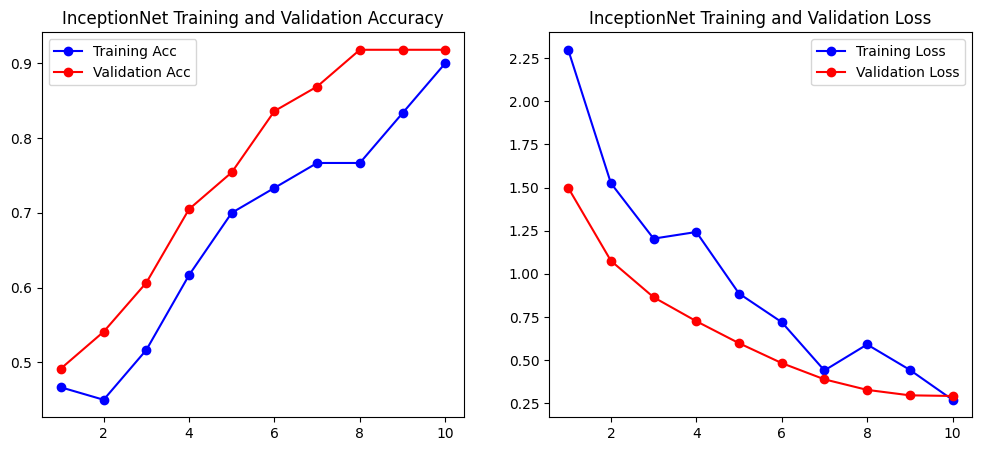

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.applications import InceptionV3 # Import InceptionV3
from tensorflow.keras.applications.inception_v3 import preprocess_input as inception_preprocess_input # Import InceptionV3-specific preprocess
import os
import glob
import matplotlib.pyplot as plt

print(f"TensorFlow 版本: {tf.__version__}")

# --- 0. 設定路徑和參數 (與先前模型相同) ---
BASE_DATA_DIR = '/content/drive/MyDrive/[0]2025深度學習/1104/data/'
train_dir = os.path.join(BASE_DATA_DIR, 'train')
validation_dir = os.path.join(BASE_DATA_DIR, 'validation')
test_dir = os.path.join(BASE_DATA_DIR, 'test')

IMG_SIZE = 128
BATCH_SIZE = 64

# --- 1. 載入與準備資料 (從本地資料夾，使用InceptionNet預處理) ---

print("正在從資料夾載入訓練資料...")
train_ds_raw = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    label_mode='binary',
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE
)

print("正在從資料夾載入驗證資料...")
validation_ds_raw = tf.keras.utils.image_dataset_from_directory(
    validation_dir,
    label_mode='binary',
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE
)

class_names = train_ds_raw.class_names
print(f"✅ 資料準備完成。類別: {class_names}")

# 由於test資料夾結構不符合image_dataset_from_directory，所以跳過創建test_ds_raw
# 並保持test_dataset為None，手動載入圖片進行預測
test_ds_raw = None # 確保 test_ds_raw 不被意外創建
test_dataset = None
print("⚠️ 警告：測試資料夾未包含預期的類別子資料夾，將跳過測試資料集 (test_ds_raw) 的創建，您可以手動載入圖片進行預測。")

# 建立前處理函式 - 使用 InceptionV3 專用的預處理
def format_image_inception(image, label):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = inception_preprocess_input(image) # 使用 InceptionV3 專用的預處理
    return image, label

AUTOTUNE = tf.data.AUTOTUNE

train_dataset_inception = train_ds_raw.map(format_image_inception).cache().prefetch(buffer_size=AUTOTUNE)
validation_dataset_inception = validation_ds_raw.map(format_image_inception).cache().prefetch(buffer_size=AUTOTUNE)

# --- 2. 建立遷移學習模型 (InceptionV3) ---

# (1) 載入 InceptionV3 基礎模型 (不含頂層分類器)
# 注意：InceptionV3 需要輸入尺寸至少為 75x75。
# 我們這裡的 IMG_SIZE=128 滿足要求。
base_model_inception = InceptionV3(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights='imagenet'
)

# (2) 凍結 InceptionV3 的捲積基底
base_model_inception.trainable = False

# 創建新的模型，在 InceptionV3 基礎上添加自定義分類層
x = base_model_inception.output
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)
predictions = Dense(1, activation='sigmoid')(x)

model_inception = Model(inputs=base_model_inception.input, outputs=predictions)

model_inception.summary()

# --- 3. 編譯與訓練模型 ---

model_inception.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("🚀 開始訓練 InceptionNet 模型...")
history_inception = model_inception.fit(
    train_dataset_inception,
    epochs=10, # 可以調整 epoch 數量
    validation_data=validation_dataset_inception
)

print("✅ 訓練完成")

# --- 4. 評估模型 (如果 test_dataset 存在，但我們跳過了) ---
if test_dataset is not None:
    print("🧪 開始評估 InceptionNet 模型在測試資料集上的表現...")
    loss, accuracy = model_inception.evaluate(test_dataset)
    print(f"測試集損失: {loss:.4f}")
    print(f"測試集準確度: {accuracy:.4f}")
else:
    print("⚠️ 未創建測試資料集 (test_dataset)，跳過模型評估。")

# --- 5. 在 Test 圖片上進行預測 (手動載入) ---
print("🧪 開始在 test 資料夾的圖片上進行預測 (手動載入圖片)...")

image_paths = []
allowed_extensions = ('.jpg', '.png', '.jpeg')

if os.path.exists(test_dir):
    for filename in os.listdir(test_dir):
        if filename.lower().endswith(allowed_extensions):
            image_paths.append(os.path.join(test_dir, filename))
else:
    print(f"錯誤：測試資料夾 '{test_dir}' 不存在。")

print(f"找到了 {len(image_paths)} 張測試圖片: {image_paths}")

for img_path in image_paths:
    img = tf.keras.utils.load_img(
        img_path, target_size=(IMG_SIZE, IMG_SIZE)
    )
    img_array = tf.keras.utils.img_to_array(img)
    # 使用 InceptionV3 專用預處理
    img_array_preprocessed = inception_preprocess_input(img_array)
    img_batch = tf.expand_dims(img_array_preprocessed, 0)

    prediction = model_inception.predict(img_batch)

    score = prediction[0][0]

    print(f"\n--- 檔案: {os.path.basename(img_path)} ---")
    print(f"原始分數: {score:.4f}")

    if score > 0.5:
        print(f"預測結果: {class_names[1]} ({score*100:.2f}%)")
    else:
        print(f"預測結果: {class_names[0]} ({(1-score)*100:.2f}%)")

# --- 6. 繪製訓練歷史 (InceptionNet 模型) ---
def plot_history_inception(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']

    epochs = range(1, len(acc) + 1)

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(epochs, acc, 'bo-', label='Training Acc')
    plt.plot(epochs, val_acc, 'ro-', label='Validation Acc')
    plt.title('InceptionNet Training and Validation Accuracy')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs, loss, 'bo-', label='Training Loss')
    plt.plot(epochs, val_loss, 'ro-', label='Validation Loss')
    plt.title('InceptionNet Training and Validation Loss')
    plt.legend()

    plt.show()

# 呼叫繪圖函式
plot_history_inception(history_inception)


## 5. MobileNetV1（遷移學習）

TensorFlow 版本: 2.19.0
正在從資料夾載入訓練資料...
Found 60 files belonging to 2 classes.
正在從資料夾載入驗證資料...
Found 61 files belonging to 2 classes.
✅ 資料準備完成。類別: ['cat', 'dog']
⚠️ 警告：測試資料夾未包含預期的類別子資料夾，將跳過測試資料集 (test_ds_raw) 的創建，您可以手動載入圖片進行預測。
17225924/17225924 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_64"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_9 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 64, 64, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_bn (BatchNormalization)   │ (None, 64, 64, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_relu (ReLU)               │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_1 (DepthwiseConv2D)     │ (None, 64, 64, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_1_bn                    │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_1_relu (ReLU)           │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_1 (Conv2D)              │ (None, 64, 64, 64)     │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_1_bn                    │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_1_relu (ReLU)           │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pad_2 (ZeroPadding2D)      │ (None, 65, 65, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_2 (DepthwiseConv2D)     │ (None, 32, 32, 64)     │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_2_bn                    │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_2_relu (ReLU)           │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_2 (Conv2D)              │ (None, 32, 32, 128)    │         8,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_2_bn                    │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_2_relu (ReLU)           │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_3 (DepthwiseConv2D)     │ (None, 32, 32, 128)    │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_3_bn                    │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_3_relu (ReLU)           │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_3 (Conv2D)              │ (None, 32, 32, 128)    │        16,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_3_bn                    │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 3,491,521 (13.32 MB)

 Trainable params: 262,657 (1.00 MB)

 Non-trainable params: 3,228,864 (12.32 MB)

🚀 開始訓練 MobileNet V1 模型...
Epoch 1/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 23s 23s/step - accuracy: 0.4000 - loss: 1.1306 - val_accuracy: 0.5574 - val_loss: 0.7663
Epoch 2/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - accuracy: 0.4333 - loss: 0.9290 - val_accuracy: 0.6066 - val_loss: 0.6929
Epoch 3/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - accuracy: 0.5333 - loss: 0.8816 - val_accuracy: 0.6557 - val_loss: 0.6323
Epoch 4/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.7000 - loss: 0.5921 - val_accuracy: 0.7377 - val_loss: 0.5832
Epoch 5/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.5833 - loss: 0.7436 - val_accuracy: 0.7705 - val_loss: 0.5406
Epoch 6/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.6333 - loss: 0.6029 - val_accuracy: 0.8033 - val_loss: 0.5037
Epoch 7/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.7167 - loss: 0.5557 - val_accuracy: 0.8361 - val_loss: 0.4701
Epoch 8/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.7667 - loss: 0.4629 - val_accuracy: 

1/1 ━━━━━━━━━━━━━━━━━━━━ 8s 8s/step

--- 檔案: 157.jpg ---
原始分數: 0.0808
預測結果: cat (91.92%)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step

--- 檔案: 159.jpg ---
原始分數: 0.7721
預測結果: dog (77.21%)


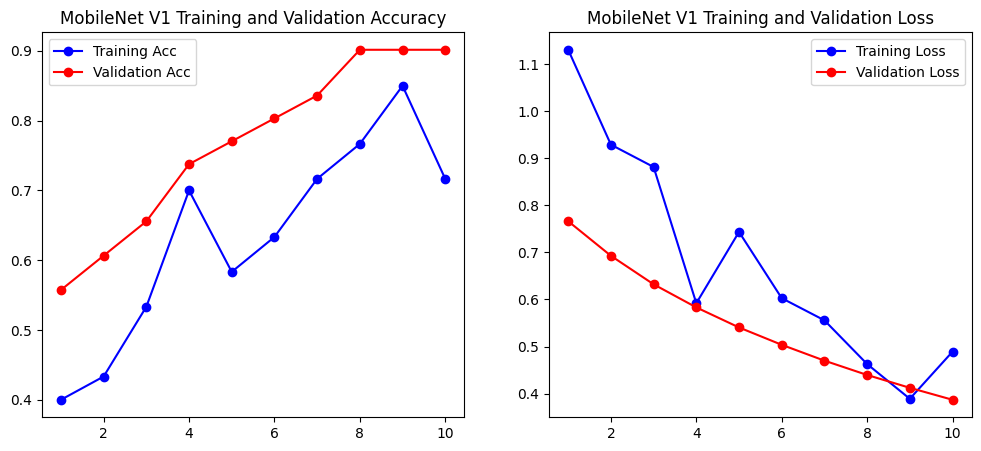

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.applications import MobileNet # Import MobileNet V1
from tensorflow.keras.applications.mobilenet import preprocess_input as mobilenet_preprocess_input # Import MobileNet-specific preprocess
import os
import glob
import matplotlib.pyplot as plt

print(f"TensorFlow 版本: {tf.__version__}")

# --- 0. 設定路徑和參數 (與先前模型相同) ---
BASE_DATA_DIR = '/content/drive/MyDrive/[0]2025深度學習/1104/data/'
train_dir = os.path.join(BASE_DATA_DIR, 'train')
validation_dir = os.path.join(BASE_DATA_DIR, 'validation')
test_dir = os.path.join(BASE_DATA_DIR, 'test')

IMG_SIZE = 128
BATCH_SIZE = 64

# --- 1. 載入與準備資料 (從本地資料夾，使用MobileNet預處理) ---

print("正在從資料夾載入訓練資料...")
train_ds_raw = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    label_mode='binary',
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE
)

print("正在從資料夾載入驗證資料...")
validation_ds_raw = tf.keras.utils.image_dataset_from_directory(
    validation_dir,
    label_mode='binary',
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE
)

class_names = train_ds_raw.class_names
print(f"✅ 資料準備完成。類別: {class_names}")

# 由於test資料夾結構不符合image_dataset_from_directory，所以跳過創建test_ds_raw
# 並保持test_dataset為None，手動載入圖片進行預測
test_ds_raw = None # 確保 test_ds_raw 不被意外創建
test_dataset = None
print("⚠️ 警告：測試資料夾未包含預期的類別子資料夾，將跳過測試資料集 (test_ds_raw) 的創建，您可以手動載入圖片進行預測。")

# 建立前處理函式 - 使用 MobileNet 專用的預處理
def format_image_mobilenet(image, label):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = mobilenet_preprocess_input(image) # 使用 MobileNet 專用的預處理
    return image, label

AUTOTUNE = tf.data.AUTOTUNE

train_dataset_mobilenet = train_ds_raw.map(format_image_mobilenet).cache().prefetch(buffer_size=AUTOTUNE)
validation_dataset_mobilenet = validation_ds_raw.map(format_image_mobilenet).cache().prefetch(buffer_size=AUTOTUNE)

# --- 2. 建立遷移學習模型 (MobileNet V1) ---

# (1) 載入 MobileNet V1 基礎模型 (不含頂層分類器)
base_model_mobilenet = MobileNet(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights='imagenet'
)

# (2) 凍結 MobileNet 的捲積基底
base_model_mobilenet.trainable = False

# 創建新的模型，在 MobileNet 基礎上添加自定義分類層
x = base_model_mobilenet.output
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)
predictions = Dense(1, activation='sigmoid')(x)

model_mobilenet = Model(inputs=base_model_mobilenet.input, outputs=predictions)

model_mobilenet.summary()

# --- 3. 編譯與訓練模型 ---

model_mobilenet.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("🚀 開始訓練 MobileNet V1 模型...")
history_mobilenet = model_mobilenet.fit(
    train_dataset_mobilenet,
    epochs=10, # 可以調整 epoch 數量
    validation_data=validation_dataset_mobilenet
)

print("✅ 訓練完成")

# --- 4. 評估模型 (如果 test_dataset 存在，但我們跳過了) ---
if test_dataset is not None:
    print("🧪 開始評估 MobileNet V1 模型在測試資料集上的表現...")
    loss, accuracy = model_mobilenet.evaluate(test_dataset)
    print(f"測試集損失: {loss:.4f}")
    print(f"測試集準確度: {accuracy:.4f}")
else:
    print("⚠️ 未創建測試資料集 (test_dataset)，跳過模型評估。")

# --- 5. 在 Test 圖片上進行預測 (手動載入) ---
print("🧪 開始在 test 資料夾的圖片上進行預測 (手動載入圖片)...")

image_paths = []
allowed_extensions = ('.jpg', '.png', '.jpeg')

if os.path.exists(test_dir):
    for filename in os.listdir(test_dir):
        if filename.lower().endswith(allowed_extensions):
            image_paths.append(os.path.join(test_dir, filename))
else:
    print(f"錯誤：測試資料夾 '{test_dir}' 不存在。")

print(f"找到了 {len(image_paths)} 張測試圖片: {image_paths}")

for img_path in image_paths:
    img = tf.keras.utils.load_img(
        img_path, target_size=(IMG_SIZE, IMG_SIZE)
    )
    img_array = tf.keras.utils.img_to_array(img)
    # 使用 MobileNet 專用預處理
    img_array_preprocessed = mobilenet_preprocess_input(img_array)
    img_batch = tf.expand_dims(img_array_preprocessed, 0)

    prediction = model_mobilenet.predict(img_batch)

    score = prediction[0][0]

    print(f"\n--- 檔案: {os.path.basename(img_path)} ---")
    print(f"原始分數: {score:.4f}")

    if score > 0.5:
        print(f"預測結果: {class_names[1]} ({score*100:.2f}%)")
    else:
        print(f"預測結果: {class_names[0]} ({(1-score)*100:.2f}%)")

# --- 6. 繪製訓練歷史 (MobileNet 模型) ---
def plot_history_mobilenet(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']

    epochs = range(1, len(acc) + 1)

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(epochs, acc, 'bo-', label='Training Acc')
    plt.plot(epochs, val_acc, 'ro-', label='Validation Acc')
    plt.title('MobileNet V1 Training and Validation Accuracy')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs, loss, 'bo-', label='Training Loss')
    plt.plot(epochs, val_loss, 'ro-', label='Validation Loss')
    plt.title('MobileNet V1 Training and Validation Loss')
    plt.legend()

    plt.show()

# 呼叫繪圖函式
plot_history_mobilenet(history_mobilenet)


In [ ]:
tf.keras.utils.plot_model(model_mobilenet, show_shapes=True, show_layer_names=True, to_file='mobilenet_model_structure.png')
from IPython.display import Image
Image(filename='mobilenet_model_structure.png')

Output hidden; open in https://colab.research.google.com to view.

## 6. EfficientNetB0（遷移學習）

TensorFlow 版本: 2.19.0
正在從資料夾載入訓練資料...
Found 60 files belonging to 2 classes.
正在從資料夾載入驗證資料...
Found 61 files belonging to 2 classes.
✅ 資料準備完成。類別: ['cat', 'dog']
⚠️ 警告：測試資料夾未包含預期的類別子資料夾，將跳過測試資料集 (test_ds_raw) 的創建，您可以手動載入圖片進行預測。
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_65"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_10      │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_5         │ (None, 128, 128,  │          0 │ input_layer_10[0… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 128, 128,  │          7 │ rescaling_5[0][0] │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_6         │ (None, 128, 128,  │          0 │ normalization[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 129, 129,  │          0 │ rescaling_6[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 64, 64,    │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 64, 64,    │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 64, 64,    │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 64, 64,    │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 64, 64,    │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 64, 64,    │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 64, 64,    │          0 │ block1a_activati… │
│ (Multiply)          │ 32)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 64, 64,    │        512 │ block1a_se_excit

 Total params: 4,377,764 (16.70 MB)

 Trainable params: 328,193 (1.25 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

🚀 開始訓練 EfficientNet 模型...
Epoch 1/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 39s 39s/step - accuracy: 0.6000 - loss: 0.6441 - val_accuracy: 0.5410 - val_loss: 0.6712
Epoch 2/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - accuracy: 0.8167 - loss: 0.5453 - val_accuracy: 0.5574 - val_loss: 0.6498
Epoch 3/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step - accuracy: 0.6833 - loss: 0.6411 - val_accuracy: 0.5574 - val_loss: 0.6292
Epoch 4/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step - accuracy: 0.7667 - loss: 0.5415 - val_accuracy: 0.5738 - val_loss: 0.6099
Epoch 5/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - accuracy: 0.7167 - loss: 0.5424 - val_accuracy: 0.5738 - val_loss: 0.5914
Epoch 6/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.7333 - loss: 0.5140 - val_accuracy: 0.5902 - val_loss: 0.5738
Epoch 7/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.8167 - loss: 0.4676 - val_accuracy: 0.6721 - val_loss: 0.5568
Epoch 8/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.8167 - loss: 0.4575 - val_accuracy: 

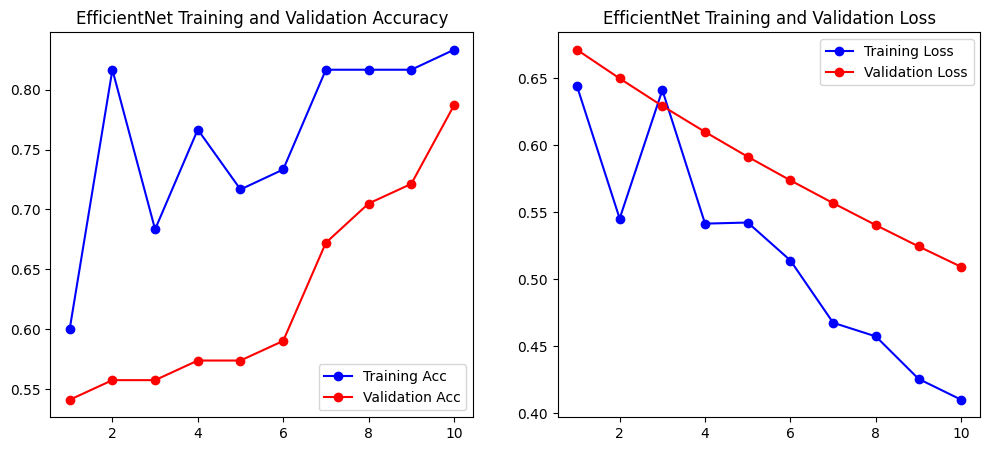

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.applications import EfficientNetB0 # Import EfficientNetB0
from tensorflow.keras.applications.efficientnet import preprocess_input as efficientnet_preprocess_input # Import EfficientNet-specific preprocess
import os
import glob
import matplotlib.pyplot as plt

print(f"TensorFlow 版本: {tf.__version__}")

# --- 0. 設定路徑和參數 (與先前模型相同) ---
BASE_DATA_DIR = '/content/drive/MyDrive/[0]2025深度學習/1104/data/'
train_dir = os.path.join(BASE_DATA_DIR, 'train')
validation_dir = os.path.join(BASE_DATA_DIR, 'validation')
test_dir = os.path.join(BASE_DATA_DIR, 'test')

IMG_SIZE = 128
BATCH_SIZE = 64

# --- 1. 載入與準備資料 (從本地資料夾，使用EfficientNet預處理) ---

print("正在從資料夾載入訓練資料...")
train_ds_raw = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    label_mode='binary',
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE
)

print("正在從資料夾載入驗證資料...")
validation_ds_raw = tf.keras.utils.image_dataset_from_directory(
    validation_dir,
    label_mode='binary',
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE
)

class_names = train_ds_raw.class_names
print(f"✅ 資料準備完成。類別: {class_names}")

# 由於test資料夾結構不符合image_dataset_from_directory，所以跳過創建test_ds_raw
# 並保持test_dataset為None，手動載入圖片進行預測
test_ds_raw = None # 確保 test_ds_raw 不被意外創建
test_dataset = None
print("⚠️ 警告：測試資料夾未包含預期的類別子資料夾，將跳過測試資料集 (test_ds_raw) 的創建，您可以手動載入圖片進行預測。")

# 建立前處理函式 - 使用 EfficientNet 專用的預處理
def format_image_efficientnet(image, label):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = efficientnet_preprocess_input(image) # 使用 EfficientNet 專用的預處理
    return image, label

AUTOTUNE = tf.data.AUTOTUNE

train_dataset_efficientnet = train_ds_raw.map(format_image_efficientnet).cache().prefetch(buffer_size=AUTOTUNE)
validation_dataset_efficientnet = validation_ds_raw.map(format_image_efficientnet).cache().prefetch(buffer_size=AUTOTUNE)

# --- 2. 建立遷移學習模型 (EfficientNetB0) ---

# (1) 載入 EfficientNetB0 基礎模型 (不含頂層分類器)
base_model_efficientnet = EfficientNetB0(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights='imagenet'
)

# (2) 凍結 EfficientNet 的捲積基底
base_model_efficientnet.trainable = False

# 創建新的模型，在 EfficientNet 基礎上添加自定義分類層
x = base_model_efficientnet.output
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)
predictions = Dense(1, activation='sigmoid')(x)

model_efficientnet = Model(inputs=base_model_efficientnet.input, outputs=predictions)

model_efficientnet.summary()

# --- 3. 編譯與訓練模型 ---

model_efficientnet.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("🚀 開始訓練 EfficientNet 模型...")
history_efficientnet = model_efficientnet.fit(
    train_dataset_efficientnet,
    epochs=10, # 可以調整 epoch 數量
    validation_data=validation_dataset_efficientnet
)

print("✅ 訓練完成")

# --- 4. 評估模型 (如果 test_dataset 存在，但我們跳過了) ---
if test_dataset is not None:
    print("🧪 開始評估 EfficientNet 模型在測試資料集上的表現...")
    loss, accuracy = model_efficientnet.evaluate(test_dataset)
    print(f"測試集損失: {loss:.4f}")
    print(f"測試集準確度: {accuracy:.4f}")
else:
    print("⚠️ 未創建測試資料集 (test_dataset)，跳過模型評估。")

# --- 5. 在 Test 圖片上進行預測 (手動載入) ---
print("🧪 開始在 test 資料夾的圖片上進行預測 (手動載入圖片)...")

image_paths = []
allowed_extensions = ('.jpg', '.png', '.jpeg')

if os.path.exists(test_dir):
    for filename in os.listdir(test_dir):
        if filename.lower().endswith(allowed_extensions):
            image_paths.append(os.path.join(test_dir, filename))
else:
    print(f"錯誤：測試資料夾 '{test_dir}' 不存在。")

print(f"找到了 {len(image_paths)} 張測試圖片: {image_paths}")

for img_path in image_paths:
    img = tf.keras.utils.load_img(
        img_path, target_size=(IMG_SIZE, IMG_SIZE)
    )
    img_array = tf.keras.utils.img_to_array(img)
    # 使用 EfficientNet 專用預處理
    img_array_preprocessed = efficientnet_preprocess_input(img_array)
    img_batch = tf.expand_dims(img_array_preprocessed, 0)

    prediction = model_efficientnet.predict(img_batch)

    score = prediction[0][0]

    print(f"\n--- 檔案: {os.path.basename(img_path)} ---")
    print(f"原始分數: {score:.4f}")

    if score > 0.5:
        print(f"預測結果: {class_names[1]} ({score*100:.2f}%)")
    else:
        print(f"預測結果: {class_names[0]} ({(1-score)*100:.2f}%)")

# --- 6. 繪製訓練歷史 (EfficientNet 模型) ---
def plot_history_efficientnet(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']

    epochs = range(1, len(acc) + 1)

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(epochs, acc, 'bo-', label='Training Acc')
    plt.plot(epochs, val_acc, 'ro-', label='Validation Acc')
    plt.title('EfficientNet Training and Validation Accuracy')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs, loss, 'bo-', label='Training Loss')
    plt.plot(epochs, val_loss, 'ro-', label='Validation Loss')
    plt.title('EfficientNet Training and Validation Loss')
    plt.legend()

    plt.show()

# 呼叫繪圖函式
plot_history_efficientnet(history_efficientnet)